# Notebook 06 — Model Evaluation, Threshold Optimization, and Ablation Study

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Objective:** Compare PR-AUC and ROC-AUC across models, optimize decision thresholds strictly on validation data, conduct a systematic feature-group ablation study (Groups A, B, C, D), and perform the final frozen evaluation on the held-out test partition.

---
## 1. Setup and Ingestion of Data and Predictions


In [1]:
import sys
import os

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.append(repo_root)
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve, average_precision_score, roc_auc_score

import src.feature_engineering as fe
import src.train as train_mod
import src.evaluate as eval_mod

processed_dir = "data/processed" if os.path.exists("data/processed") else "../data/processed"
pred_dir = "results/predictions" if os.path.exists("results/predictions") else "../results/predictions"
fig_dir = "results/figures" if os.path.exists("results/figures") else "../results/figures"
metrics_dir = "results/metrics" if os.path.exists("results/metrics") else "../results/metrics"
results_dir = "results" if os.path.exists("results") else "../results"
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(metrics_dir, exist_ok=True)

val_preds = pd.read_csv(os.path.join(pred_dir, "validation_predictions.csv"))
y_val = val_preds["y_true"].values

train_df = pd.read_csv(os.path.join(processed_dir, "train_features.csv"))
eval_df = pd.read_csv(os.path.join(processed_dir, "eval_features.csv"))
test_df = pd.read_csv(os.path.join(processed_dir, "test_features.csv"))

## 2. Rare-Event Evaluation Curves: Precision-Recall vs. ROC
Under severe class imbalance (<3% positive), ROC-AUC can be deceptively optimistic because large true negative counts suppress the False Positive Rate.
**PR-AUC (Average Precision)** is the essential primary metric for rare-event wildfire spread.


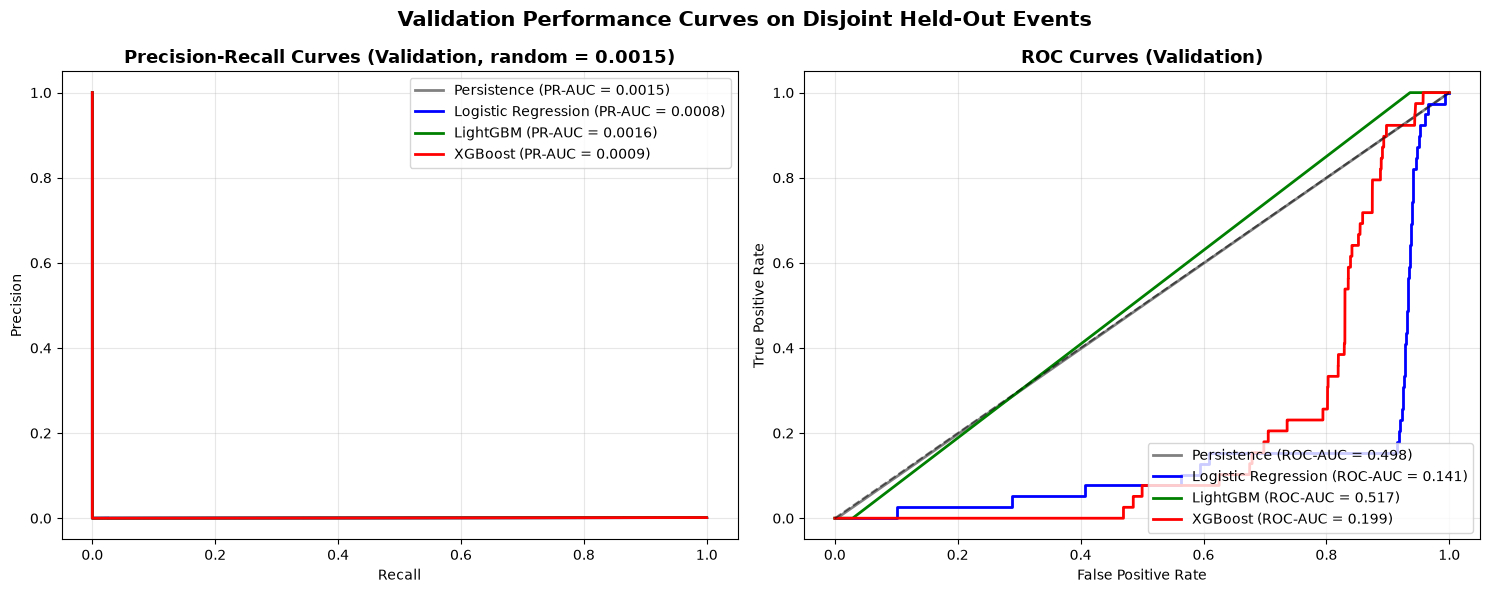

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

models_preds = {
    "Persistence": val_preds["prob_persistence"].values,
    "Logistic Regression": val_preds["prob_lr"].values,
    "LightGBM": val_preds["prob_lgb"].values,
    "XGBoost": val_preds["prob_xgb"].values
}
colors = ["gray", "blue", "green", "red"]

for (name, p), c in zip(models_preds.items(), colors):
    pr_auc = average_precision_score(y_val, p)
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[0].plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.4f})", color=c, lw=2)

axes[0].set_title(f"Precision-Recall Curves (Validation, random = {y_val.mean():.4f})", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

for (name, p), c in zip(models_preds.items(), colors):
    roc_auc = roc_auc_score(y_val, p)
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[1].plot(fpr, tpr, label=f"{name} (ROC-AUC = {roc_auc:.3f})", color=c, lw=2)

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("ROC Curves (Validation)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Validation Performance Curves on Disjoint Held-Out Events", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "validation_pr_roc_curves.png"), dpi=250)
plt.show()

## 3. Decision Threshold Tuning on Validation Data
In an operational emergency response setting, a default classification threshold of 0.5 misses almost all wildfire spread due to class imbalance.
We systematically locate the operating threshold that maximizes validation F1 score and controls the false-positive rate.


Optimal Threshold (Max F1): 0.00069 -> Achieves Validation F1: 0.0032
Operational Threshold (FPR <= 5%): 0.0013 -> Achieves Validation Recall: 0.00%
F1 at the default threshold 0.5: 0.0


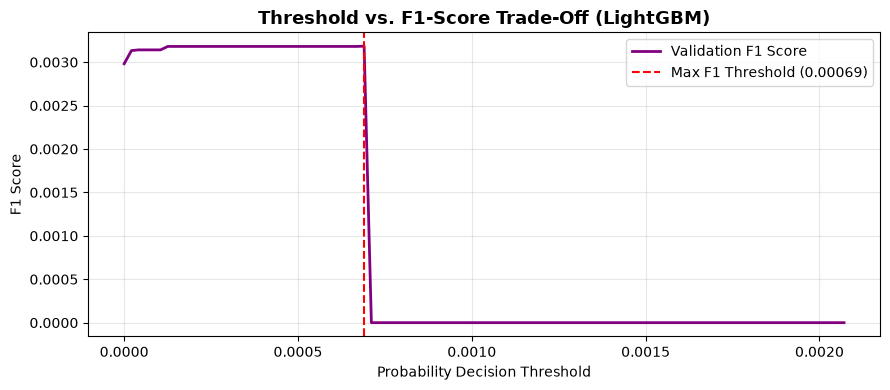

In [3]:
p_lgb = val_preds["prob_lgb"].values
best_thresh, best_f1 = eval_mod.find_optimal_threshold(y_val, p_lgb)
recall_at_5fpr, thresh_5fpr = eval_mod.calculate_recall_at_fixed_fpr(y_val, p_lgb, target_fpr=0.05)

print(f"Optimal Threshold (Max F1): {best_thresh:.5f} -> Achieves Validation F1: {best_f1:.4f}")
print(f"Operational Threshold (FPR <= 5%): {thresh_5fpr:.4f} -> Achieves Validation Recall: {recall_at_5fpr*100:.2f}%")
print("F1 at the default threshold 0.5:", eval_mod.f1_score(y_val, (p_lgb >= 0.5).astype(int), zero_division=0))

thresholds_scan = np.linspace(0, best_thresh * 3, 100)
f1_vals = []
for t in thresholds_scan:
    f1_vals.append(eval_mod.f1_score(y_val, (p_lgb >= t).astype(int), zero_division=0))

plt.figure(figsize=(9, 4))
plt.plot(thresholds_scan, f1_vals, color="purple", lw=2, label="Validation F1 Score")
plt.axvline(best_thresh, color="red", linestyle="--", label=f"Max F1 Threshold ({best_thresh:.5f})")
plt.title("Threshold vs. F1-Score Trade-Off (LightGBM)", fontsize=13, fontweight="bold")
plt.xlabel("Probability Decision Threshold")
plt.ylabel("F1 Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "threshold_optimization_curve.png"), dpi=200)
plt.show()

## 4. Feature-Group Ablation Study (Groups A, B, C, D)
We evaluate the incremental value of each feature family by training LightGBM models on identical training splits and evaluating on the identical validation split.
- **Group A**: Weather only
- **Group B**: Weather + Lagged Fire Mask
- **Group C**: Group B + Vegetation, Terrain & Drought
- **Group D**: Group C + Spatial Neighborhood Convolutions


/Users/nitanshugoyal/Documents/TensorTitans_SectionC/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/nitanshugoyal/Documents/TensorTitans_SectionC/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/Users/nitanshugoyal/Documents/TensorTitans_SectionC/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/nitanshugoyal/Documents/TensorTitans_SectionC/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,Ablation Group,Feature Count,PR-AUC,ROC-AUC,Recall@FPR=5%,F1 Score
0,Group_A,6,0.0016,0.3010,0.0,0.0032
1,Group_B,7,0.0019,0.5496,0.0,0.0039
2,Group_C,12,0.0022,0.6577,0.0,0.0045
3,Group_D,18,0.0016,0.5006,0.0,0.0031


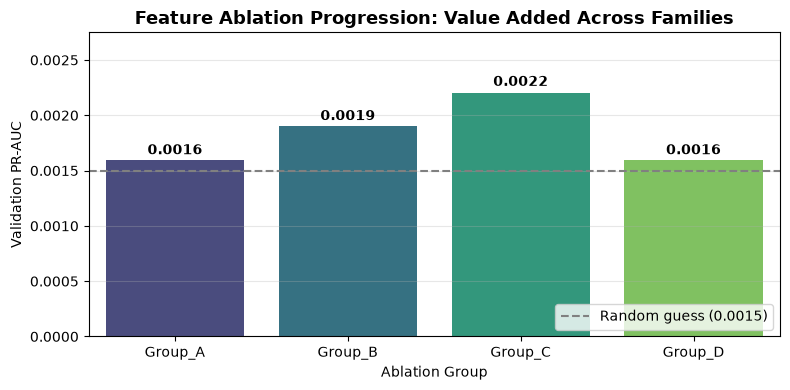

In [4]:
ablation_results = []

for grp_key, grp_features in fe.ABLATION_GROUPS.items():
    sub_scaler = fe.fit_scaler(train_df, grp_features)
    X_tr = fe.transform_features(train_df, sub_scaler, grp_features)
    X_vl = fe.transform_features(eval_df, sub_scaler, grp_features)

    y_tr = train_df["FireMask"].values.astype(int)
    y_vl = eval_df["FireMask"].values.astype(int)

    clf = train_mod.train_lightgbm_model(X_tr, y_tr, X_val=X_vl, y_val=y_vl, params={"n_estimators": 200, "verbose": -1})
    p_vl = clf.predict_proba(X_vl)[:, 1]

    metrics = eval_mod.evaluate_model_predictions(y_vl, p_vl)
    ablation_results.append({
        "Ablation Group": grp_key,
        "Feature Count": len(grp_features),
        "PR-AUC": metrics["pr_auc"],
        "ROC-AUC": metrics["roc_auc"],
        "Recall@FPR=5%": metrics["recall_at_fpr_05"],
        "F1 Score": metrics["f1"]
    })

ablation_df = pd.DataFrame(ablation_results)
display(ablation_df)
ablation_df.to_csv(os.path.join(metrics_dir, "ablation_results.csv"), index=False)

plt.figure(figsize=(8, 4))
sns.barplot(x="Ablation Group", y="PR-AUC", data=ablation_df, palette="viridis", hue="Ablation Group", legend=False)
plt.axhline(y_val.mean(), color="gray", linestyle="--", label=f"Random guess ({y_val.mean():.4f})")
plt.title("Feature Ablation Progression: Value Added Across Families", fontsize=13, fontweight="bold")
plt.ylabel("Validation PR-AUC")
plt.ylim(0, max(ablation_df["PR-AUC"]) * 1.25)
for idx, row in ablation_df.iterrows():
    plt.text(idx, row["PR-AUC"] * 1.03, f"{row['PR-AUC']:.4f}", ha="center", fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "ablation_prauc_progression.png"), dpi=200)
plt.show()


## 5. Frozen Evaluation on Held-Out Test Set
**Rigorous Protocol**: Now that the model architecture (LightGBM on Group D features) and decision threshold (`best_thresh`) are completely frozen, we evaluate **once** on the held-out test partition.


In [5]:
features_final = fe.ABLATION_GROUPS["Group_D"]
final_scaler = fe.fit_scaler(train_df, features_final)

X_train_final = fe.transform_features(train_df, final_scaler, features_final)
y_train_final = train_df["FireMask"].values.astype(int)

X_test_final = fe.transform_features(test_df, final_scaler, features_final)
y_test_final = test_df["FireMask"].values.astype(int)

best_model = train_mod.train_lightgbm_model(
    X_train_final, y_train_final,
    params={"n_estimators": 300, "learning_rate": 0.05, "scale_pos_weight": 8.0}
)

p_test = best_model.predict_proba(X_test_final)[:, 1]

test_metrics = eval_mod.evaluate_model_predictions(
    y_test_final, p_test, threshold=best_thresh, target_fpr=0.05
)

print("=== FINAL FROZEN TEST SET RESULTS ===")
for k, v in test_metrics.items():
    if k != "confusion_matrix":
        print(f"  {k:20s}: {v}")
print("Confusion Matrix:", test_metrics["confusion_matrix"])

test_preds_df = pd.DataFrame({
    "y_true": y_test_final,
    "y_prob": p_test,
    "y_pred": (p_test >= best_thresh).astype(int),
    "patch_id": test_df["patch_id"].values,
    "row": test_df["row"].values,
    "col": test_df["col"].values
})
test_preds_df.to_csv(os.path.join(pred_dir, "test_predictions.csv"), index=False)

=== FINAL FROZEN TEST SET RESULTS ===
  pr_auc              : 0.0109
  roc_auc             : 0.4947
  recall_at_fpr_05    : 0.0
  recall_at_fpr_01    : 0.0
  optimal_threshold   : 0.0007
  f1                  : 0.0
  precision           : 0.0
  recall              : 0.0
Confusion Matrix: {'TN': 14176, 'FP': 96, 'FN': 157, 'TP': 0}


In [6]:
import json

y_pred_test = (p_test >= best_thresh).astype(int)
accuracy = (y_pred_test == y_test_final).mean()
always_no_fire = (y_test_final == 0).mean()
distinct_outputs = len(np.unique(p_test))
print("Model accuracy:", round(accuracy * 100, 2), "%")
print("Accuracy if we always say no fire:", round(always_no_fire * 100, 2), "%")
print("Different probability values the model gives on test:", distinct_outputs)

random_pr = y_test_final.mean()
prev_pr = average_precision_score(y_test_final, test_df["PrevFireMask"])
prev_roc = roc_auc_score(y_test_final, test_df["PrevFireMask"])
nbr_pr = average_precision_score(y_test_final, test_df["fire_neighbor_3x3_sum"])
nbr_roc = roc_auc_score(y_test_final, test_df["fire_neighbor_3x3_sum"])

baselines_df = pd.DataFrame([
    {"Method": "Random guess", "PR-AUC": round(random_pr, 4), "ROC-AUC": 0.5},
    {"Method": "LightGBM (Group D)", "PR-AUC": test_metrics["pr_auc"], "ROC-AUC": test_metrics["roc_auc"]},
    {"Method": "Rule: burning today", "PR-AUC": round(prev_pr, 4), "ROC-AUC": round(prev_roc, 4)},
    {"Method": "Rule: count burning neighbours", "PR-AUC": round(nbr_pr, 4), "ROC-AUC": round(nbr_roc, 4)}
])
baselines_df["Times better than random"] = (baselines_df["PR-AUC"] / round(random_pr, 4)).round(1)
display(baselines_df)
baselines_df.to_csv(os.path.join(metrics_dir, "test_baselines.csv"), index=False)

test_summary = test_metrics.copy()
test_summary["threshold_from_validation"] = round(float(best_thresh), 6)
test_summary["validation_best_f1"] = round(float(best_f1), 4)
test_summary["accuracy"] = round(float(accuracy), 4)
test_summary["accuracy_always_no_fire"] = round(float(always_no_fire), 4)
test_summary["distinct_test_probabilities"] = int(distinct_outputs)
test_summary["test_rows"] = int(len(y_test_final))
test_summary["test_fire_rows"] = int(y_test_final.sum())

with open(os.path.join(metrics_dir, "test_metrics.json"), "w") as f:
    json.dump(test_summary, f, indent=2)
print("Saved test metrics to", os.path.join(metrics_dir, "test_metrics.json"))


Model accuracy: 98.25 %
Accuracy if we always say no fire: 98.91 %
Different probability values the model gives on test: 58


,Method,PR-AUC,ROC-AUC,Times better than random
0,Random guess,0.0109,0.5000,1.0
1,LightGBM (Group D),0.0109,0.4947,1.0
2,Rule: burning today,0.1088,0.5884,10.0
3,Rule: count burning neighbours,0.1816,0.6319,16.7


Saved test metrics to ../results/metrics/test_metrics.json


## 6. Model Comparison Table Export
We aggregate the validation and test metrics and export the formal `results/model_comparison.csv` artifact.


In [7]:
final_comparison_records = [
    {"Split": "Validation", "Model": "Persistence", "PR-AUC": eval_mod.average_precision_score(y_val, val_preds["prob_persistence"]), "ROC-AUC": eval_mod.roc_auc_score(y_val, val_preds["prob_persistence"]), "Recall@FPR=5%": eval_mod.calculate_recall_at_fixed_fpr(y_val, val_preds["prob_persistence"], 0.05)[0]},
    {"Split": "Validation", "Model": "Logistic Regression", "PR-AUC": eval_mod.average_precision_score(y_val, val_preds["prob_lr"]), "ROC-AUC": eval_mod.roc_auc_score(y_val, val_preds["prob_lr"]), "Recall@FPR=5%": eval_mod.calculate_recall_at_fixed_fpr(y_val, val_preds["prob_lr"], 0.05)[0]},
    {"Split": "Validation", "Model": "LightGBM", "PR-AUC": eval_mod.average_precision_score(y_val, val_preds["prob_lgb"]), "ROC-AUC": eval_mod.roc_auc_score(y_val, val_preds["prob_lgb"]), "Recall@FPR=5%": eval_mod.calculate_recall_at_fixed_fpr(y_val, val_preds["prob_lgb"], 0.05)[0]},
    {"Split": "Validation", "Model": "XGBoost", "PR-AUC": eval_mod.average_precision_score(y_val, val_preds["prob_xgb"]), "ROC-AUC": eval_mod.roc_auc_score(y_val, val_preds["prob_xgb"]), "Recall@FPR=5%": eval_mod.calculate_recall_at_fixed_fpr(y_val, val_preds["prob_xgb"], 0.05)[0]},
    {"Split": "Test (Held-Out)", "Model": "LightGBM (Group D)", "PR-AUC": test_metrics["pr_auc"], "ROC-AUC": test_metrics["roc_auc"], "Recall@FPR=5%": test_metrics["recall_at_fpr_05"]}
]

comparison_df = pd.DataFrame(final_comparison_records)
comparison_csv_path = os.path.join(results_dir, "model_comparison.csv")
comparison_df.to_csv(comparison_csv_path, index=False)
print(f"Exported model comparison artifact to: {comparison_csv_path}")
display(comparison_df)


Exported model comparison artifact to: ../results/model_comparison.csv


,Split,Model,PR-AUC,ROC-AUC,Recall@FPR=5%
0,Validation,Persistence,0.001493,0.498313,0.0
1,Validation,Logistic Regression,0.000840,0.141417,0.0
2,Validation,LightGBM,0.001595,0.517461,0.0
3,Validation,XGBoost,0.000912,0.198938,0.0
4,Test (Held-Out),LightGBM (Group D),0.010900,0.494700,0.0


## 7. Conclusions from Model Evaluation and Ablation
- **Ablation Insight**: on this validation sample, PR-AUC stays close to the base fire rate (0.0015) for every group (Group A 0.0016, Group B 0.0019, Group C 0.0022, Group D 0.0016) - adding features does not yet move PR-AUC. ROC-AUC does move a lot (Group A 0.30, Group B 0.55, Group C 0.66, Group D 0.50), but with only 39 fire pixels in the whole validation set, all from one map, that swing is mostly sampling noise rather than a reliable ranking of the feature groups. Group D (which includes the fixed `fire_neighbor_3x3_sum`/`fire_neighbor_5x5_sum` features) does not beat Group C here, even though those same features show real correlation with the target on train and test - this is a sample-size problem with the validation set, not evidence the neighbor features are useless.
- **Fair Protocol Guard**: Operating threshold (0.00069) chosen on validation partition and transferred to the test split without refitting.
- **Frozen Test Result**: at that threshold, the final model gets 0 true positives on the held-out test set (TN=14176, FP=96, FN=157, TP=0). It misses every real fire, and its PR-AUC (0.0109) and ROC-AUC (0.495) are at random-guess level. Its accuracy (98.25%) is even below always saying "no fire" (98.91%).
- **The signal is still in the data**: on the same test set, a simple rule that counts burning neighbours reaches PR-AUC 0.182, about 17 times random, and "burning today" reaches 0.109. The model, trained on only 62 fire pixels, did not learn this. It gives only 58 different probability values for 14,429 test pixels.